# YAMNet Model

The goal of this notebook is to practice using Google's pretrained YAMNet model to create an audio classification neural network. Unlike the other CNNs in this project, YAMNet operates directly on WAV files, rather than on spectrograms, which are used by the other CNN models. YAMNet is specifically for audio classification.

https://www.geeksforgeeks.org/deep-learning/audio-classification-using-googles-yamnet/,  and https://www.tensorflow.org/hub/tutorials/yamnet were useful sources and AI was used when error messages appeared.

### 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import Audio
import scipy
import soundfile as sf
import tensorflow as tf
import tensorflow_hub as hub
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [15]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vinayshanbhag/bird-song-data-set")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\hilda\.cache\kagglehub\datasets\vinayshanbhag\bird-song-data-set\versions\1


### 2. Data preprocessing

Let's preprocess the data. YAMNet is trained with 16 kHz, so let's make sure the data matches it. Audio recordings can have multiple channels, but YAMNet expects mono audio, so let's change the audio shape as well.

In [16]:
DESIRED_SR = 16000

def load_and_resample(file_path, desired_sample_rate=DESIRED_SR):
    audio, sr = sf.read(file_path)

    # if audio is stereo shape, change it to mono
    if len(audio.shape) > 1:
        audio = np.mean(audio, axis=1)

    # sample rate change to 16 khz, because yamnet model was trained at 16 khz
    if sr != desired_sample_rate:
        num_samples = int(len(audio) * desired_sample_rate / sr)
        audio = scipy.signal.resample(audio, num_samples)
        sr = desired_sample_rate

    return sr, np.array(audio, dtype=np.float32)


In [17]:
# Load metadata from local CSV
df = pd.read_csv("./data/bird_songs_metadata.csv/bird_songs_metadata.csv")
# Construct full paths to audio files in downloaded dataset (wavfiles subdirectory)
df["full_path"] = df["filename"].apply(lambda x: f"{path}/wavfiles/{x.split('/')[-1]}")
df.head(3)

,id,genus,species,subspecies,name,recordist,country,location,latitude,longitude,altitude,sound_type,source_url,license,time,date,remarks,filename,full_path
0,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-0.wav,C:\Users\hilda\.cache\kagglehub\datasets\vinay...
1,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-1.wav,C:\Users\hilda\.cache\kagglehub\datasets\vinay...
2,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-4.wav,C:\Users\hilda\.cache\kagglehub\datasets\vinay...


Let's load audio records from disk.

In [18]:
audio_records = []

for idx, row in df.iterrows():

    fname = os.path.basename(row["filename"])
    file_path = os.path.join(path, "wavfiles", fname)

    if not os.path.exists(file_path):
        print("Missing file:", file_path)
        continue

    try:
        sr, waveform = load_and_resample(file_path)
        audio_records.append([waveform, row["species"]])
    except Exception as e:
        print(f"Error reading {file_path}: {e}")


Creating a dataframe 

In [ ]:
audio_df = pd.DataFrame(audio_records, columns=["audio_data", "class"])
print(audio_df.head())
print("Total loaded files:", len(audio_df))


                                          audio_data     class
0  [-0.0402493, -0.04265199, -0.14397871, -0.1465...  bewickii
1  [0.25818744, 0.15129878, 0.08177614, 0.1679952...  bewickii
2  [0.027286107, 0.04876928, 0.013345121, 0.06286...  bewickii
3  [0.24556233, 0.26591614, 0.23912756, 0.2240397...  bewickii
4  [-0.009142286, 0.044882312, 0.099073105, 0.149...  bewickii
Total loaded files: 5422


Loading Google's YAMNet model.

In [20]:
yamnet_model = hub.load("https://tfhub.dev/google/yamnet/1")
print("YAMNet loaded.")

YAMNet loaded.


Let's create a function that turns the original waveform data to tensors, that the YAMNet can use. YAMNet needs 1024-dimensional vectors.

In [21]:
def extract_embedding(waveform):
    waveform_tf = tf.convert_to_tensor(waveform, dtype=tf.float32)
    scores, embeddings, spectrogram = yamnet_model(waveform_tf)

    # embeddings shape: (num_frames, 1024)
    embedding = tf.reduce_mean(embeddings, axis=0)
    return embedding.numpy()


Let's utilize the function and attach corresponding class label to the tensor.

In [22]:
X = []
y = []

for waveform, label in audio_records:
    emb = extract_embedding(waveform)
    X.append(emb)
    y.append(label)

X = np.array(X)
y = np.array(y)
print(X.shape, y.shape)


(5422, 1024) (5422,)


Changing the string labels to numbers that the model can use.

In [23]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
num_classes = len(le.classes_)

print("Classes:", le.classes_)


Classes: ['bewickii' 'cardinalis' 'melodia' 'migratorius' 'polyglottos']


Splitting the data to test and training sets.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)


### 3. Model architecture

A simple FCN model on top of the pretrained model. The shape 1024 comes from the YAMNet as an output.

In [25]:
model = models.Sequential([
    layers.Input(shape=(1024,)),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 657,413 (2.51 MB)

 Trainable params: 657,413 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Training the model

Training the model with early stopping to help prevent overfitting.

In [26]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.4546 - loss: 1.2715 - val_accuracy: 0.5853 - val_loss: 1.0267
Epoch 2/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6160 - loss: 0.9667 - val_accuracy: 0.6440 - val_loss: 0.8974
Epoch 3/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6587 - loss: 0.8586 - val_accuracy: 0.6912 - val_loss: 0.8182
Epoch 4/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6884 - loss: 0.7901 - val_accuracy: 0.7247 - val_loss: 0.7336
Epoch 5/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7100 - loss: 0.7321 - val_accuracy: 0.7350 - val_loss: 0.7057
Epoch 6/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7377 - loss: 0.6833 - val_accuracy: 0.6947 - val_loss: 0.7618
Epoch 7/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7590 - loss: 0.6209 - val_accuracy: 0.7419 - val_loss: 0.6597
Epoch 8/40
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7795 - loss: 0.5947 - val_accu

### 5. Evaluation

The results are pretty good with accuracy of 80% and loss of 0.6141.

In [27]:
loss, acc = model.evaluate(X_test, y_test)
print("Test accuracy:", acc)


34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7954 - loss: 0.6141
Test accuracy: 0.7953916788101196


34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


<Figure size 1200x800 with 0 Axes>

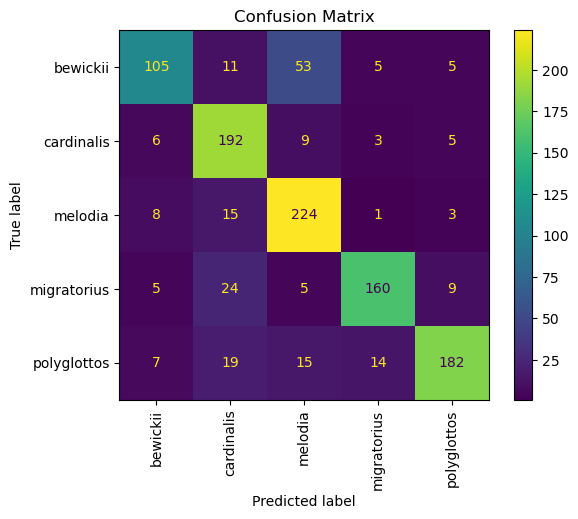

In [28]:
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)

plt.figure(figsize=(12,8))
disp.plot(xticks_rotation='vertical')
plt.title("Confusion Matrix")
plt.show()

As seen from the confusion matrix, most samples are classified correctly. The largest misclassification happens with the species "bewickii" that is misclassified as "melodia".

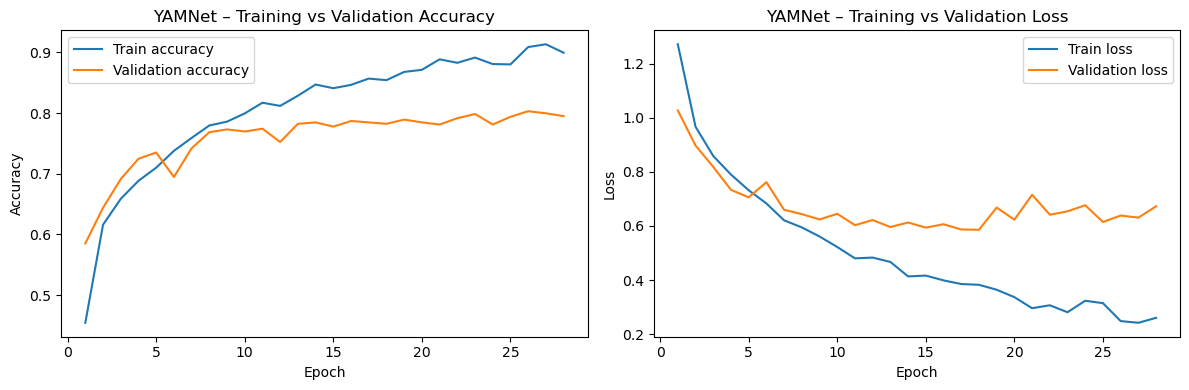

In [29]:
train_acc = history.history["accuracy"]
val_acc   = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss   = history.history["val_loss"]
epochs = range(1, len(train_acc) + 1)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(epochs, train_acc, label="Train accuracy")
plt.plot(epochs, val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("YAMNet – Training vs Validation Accuracy")

plt.subplot(1,2,2)
plt.plot(epochs, train_loss, label="Train loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("YAMNet – Training vs Validation Loss")

plt.tight_layout()
plt.show()

As seen from the accuracy and loss plots, there's space between accuracy and loss curves, which indicates slight overfitting. Overall the model performs well, though there's room for improvement. 